# Solo flujo glótico

In [3]:
import numpy as np
from scipy.io import wavfile
import IPython.display as ipd
from scipy import signal as sig
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'

In [4]:
# Parámetros para hacer el recorte temporal de la señal
fs_r = 8000

to = 800/1000
tf = 830/1000

no = int(np.round(to * fs_r)) 
nf = int(np.round(tf * fs_r)) 

tiempos       = (1000/fs_r)*np.arange(0,nf-no)


#==========================================================================================================================================================================#
#archivo = "M01_normal_low"

archivo_mic         = 'Repositorio II/RepositoryII_male/Male_A_82Hz_large.wav'
fs_mic,señales = wavfile.read(archivo_mic)

señales   = sig.resample(señales, len(señales)*fs_r//fs_mic)

señal_mic = señales[no:nf][:,1]
señal_mic = señal_mic/max(señal_mic)
señal_mic -=0.9*min(señal_mic) 

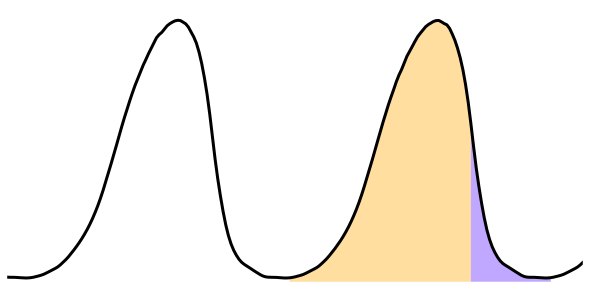

In [11]:
fig,ax = plt.subplots(figsize=(8,4))
ax.plot(tiempos,señal_mic,linewidth=3,color='k');
color1 ="#FFBF4985"
color2 ="#9064FF90"
# Máscaras para cada rango (asumiendo que 'tiempos' está en ms)
mask1 = (tiempos >= 13.25) & (tiempos <= 21.75)
mask2 = (tiempos >= 21.75) & (tiempos <= 25.5)

ax.fill_between(tiempos, señal_mic, 0, where=mask1, color=color1,edgecolor='none')
ax.fill_between(tiempos, señal_mic, 0, where=mask2, color=color2,edgecolor='none')
# Quitar los ejes y el marco
ax.axis('off')
ax.set_xlim([0,27])
# Ajustar los márgenes para que solo se vea la curva
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig('flujo.svg')

# ACC, OVV, MIC

In [14]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import Funciones as Funciones
import NNMF_GIF as NMF
from pathlib import Path
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import  clear_output
import pandas as pd
#%config InlineBackend.figure_format = 'svg'
import librosa as lib

In [15]:
FC = FileChooser('Señales VEC')
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales VEC', filename='', title='', show_hidden=Fal…

In [16]:
filtro_pb            = 'Chebyshev II'
#filtro_pb           = 'Butterworth'
orden_filtro_pb      = 10
atenuacion_filtro_pb = 40
fc_filtro_pb         = 1100
orden_filtro_pa      = 6
fc_filtro_pa         = 60
metrica = 1

In [18]:
archivo = Path(FC.selected)
nombre_archivo = archivo.name

df = pd.read_csv(FC.selected, sep=',')

tiempos      = df['t_ms'].values
OVV_original = df['OVV'].values


linewidth = 2
alfa_grid = 0.3
to = 0
tf = 30

color_notch = 'red'
color_lpc  = 'orange'
color_flujo = 'k'
color1 = 'red'
color2 = 'blue'


linewidth   = 2
fs_r        = 8000
color_notch = 'red'

OVV_original                   = OVV_original / max(abs(OVV_original))
OVV_filtrada_pb, b_pb, a_pb    = Funciones.LP_Filter(OVV_original, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
w_pb, h_pb                     = sig.freqz(b_pb, a_pb, fs=fs_r)
OVV_filtrada_pb_pa, b_pa, a_pa = Funciones.HP_Filter(OVV_filtrada_pb, fs=fs_r)

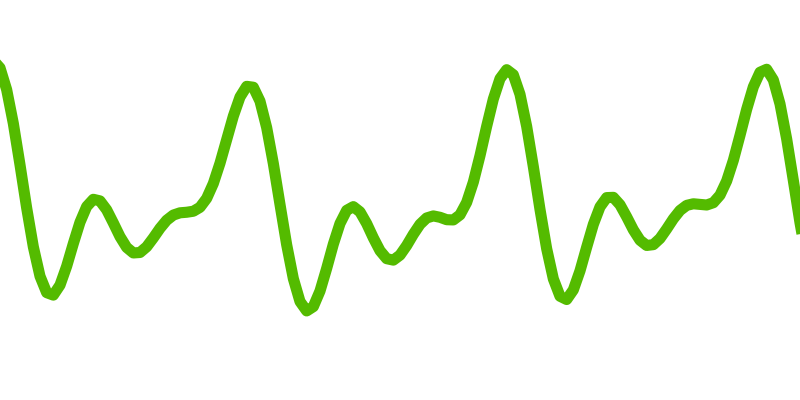

In [19]:
fig,ax = plt.subplots(figsize=(8,4))
color = "#54BB00"
ax.plot(tiempos,OVV_filtrada_pb_pa,linewidth=8,color=color);
# Quitar los ejes y el marco
ax.set_xlim([10,25])
ax.axis('off')

# Ajustar los márgenes para que solo se vea la curva
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig('OVV.svg')

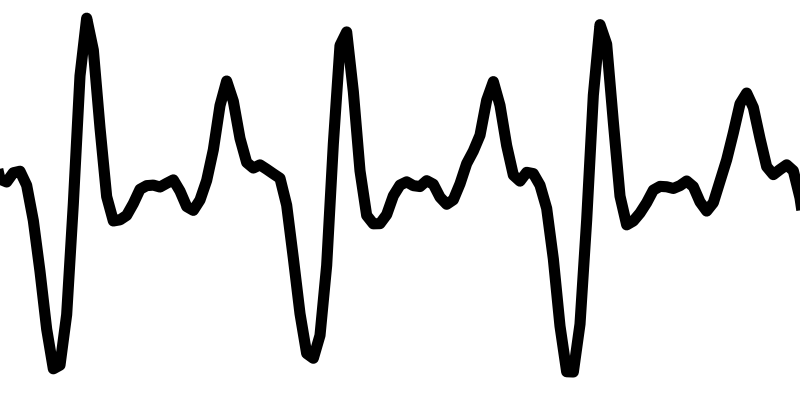

In [20]:
fig,ax = plt.subplots(figsize=(8,4))
ax.plot(tiempos,df['MBK'].values,linewidth=8,color='k');
# Quitar los ejes y el marco
ax.set_xlim([10,25])
ax.axis('off')

# Ajustar los márgenes para que solo se vea la curva
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig('MIC.svg')

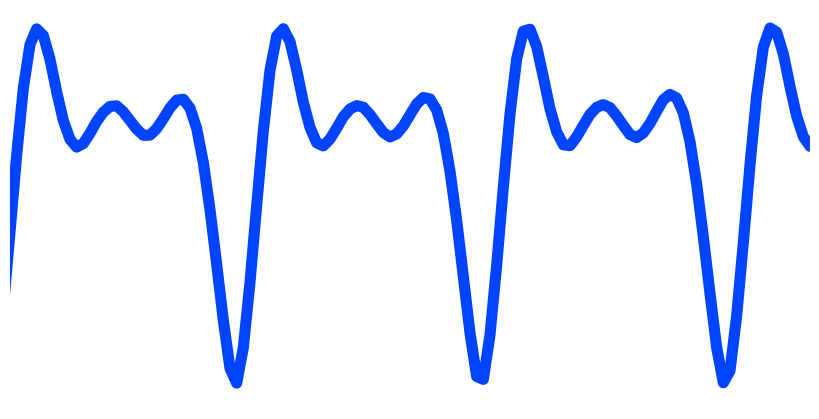

In [46]:
fig,ax = plt.subplots(figsize=(8,4))
color = "#0044FF"
ax.plot(tiempos,-df['ACC'].values,linewidth=8,color=color);
# Quitar los ejes y el marco
ax.set_xlim([10,25])
ax.axis('off')

# Ajustar los márgenes para que solo se vea la curva
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig('ACC.svg')

# Figuras diagrama de bloques fuente filtro

In [13]:
import numpy as np
from scipy.io import wavfile
import IPython.display as ipd
from scipy import signal as sig
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = 'svg'


In [20]:
# Parámetros para hacer el recorte temporal de la señal
fs_r = 8000

to = 800/1000
tf = 830/1000

no = int(np.round(to * fs_r)) 
nf = int(np.round(tf * fs_r)) 

tiempos       = (1000/fs_r)*np.arange(0,nf-no)


#==========================================================================================================================================================================#
#archivo = "M01_normal_low"

archivo_mic         = 'Repositorio II/RepositoryII_male/Male_A_82Hz_large.wav'
fs_mic,señales = wavfile.read(archivo_mic)

señales   = sig.resample(señales, len(señales)*fs_r//fs_mic)

flujo = señales[no:nf][:,1]
flujo = flujo/max(flujo)
flujo -=0.9*min(flujo)

mic = señales[no:nf][:,0]
mic = mic/max(abs(mic))

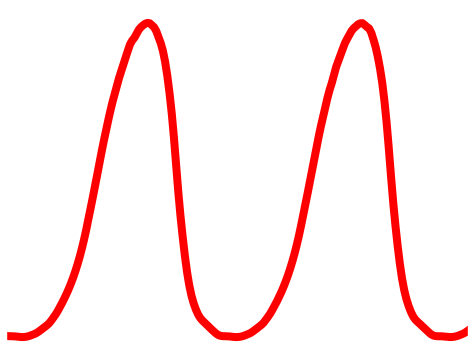

In [29]:
fig,ax = plt.subplots()


ax.set_xlim([0,210])
ax.axis('off')
color1 ="#FF0000FF"
ax.plot(flujo,color=color1,linewidth=8)
# Ajustar los márgenes para que solo se vea la curva
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig('flujo_bloques.svg')

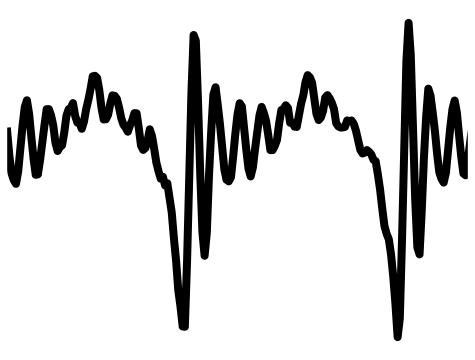

In [28]:
fig,ax = plt.subplots()
ax.set_xlim([0,210])
ax.axis('off')
color1 ="#FF0000FF"
ax.plot(mic,color='k',linewidth=8)
# Ajustar los márgenes para que solo se vea la curva
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig('mic_bloques.svg')

In [2]:
import numpy as np
from scipy.io import loadmat
import ipywidgets as widgets
from scipy.signal import resample
import os 
from pathlib import Path
import matplotlib.pyplot as plt
from ipywidgets import IntRangeSlider, VBox, HBox, Output,Label
from IPython.display import display, Audio
from ipyfilechooser import FileChooser
import pandas as pd
import Funciones as Funciones

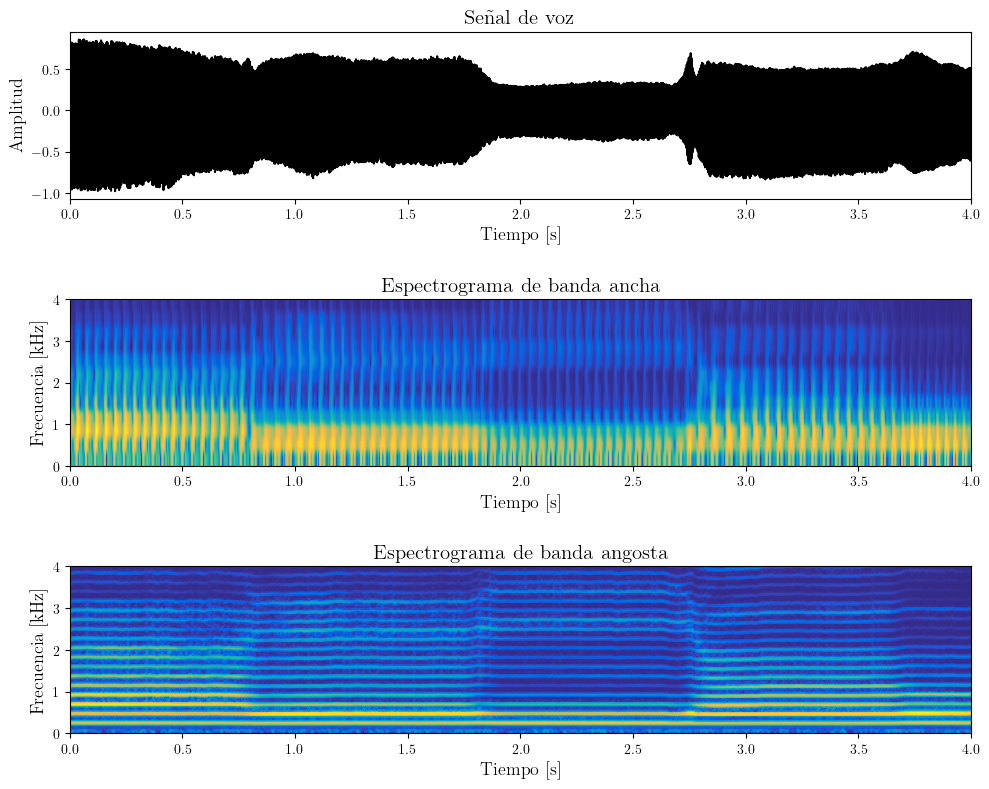

In [ ]:
import numpy as np
import pandas as pd
import IPython.display as ipd
from scipy import signal
import matplotlib.pyplot as plt
cmap = Funciones.parula_map
df = pd.read_csv("signal.csv")
t = df["time"].values
data = df["amplitude"].values
fs = 20000

# resample to 8kHz for better visualization
target_fs = 8000
data = signal.resample(data, len(data)*target_fs//fs)
fs = target_fs

ipd.display(ipd.Audio(data, rate=fs))
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']
# ---------------------------------------------------------
# Función auxiliar para calcular un espectrograma dado un
# largo de ventana (en ms) y un paso (en ms)
# ---------------------------------------------------------
def compute_spectrogram(data, fs, window_length_ms, window_step_ms):
    window_step = int(np.round(fs*window_step_ms/1000))
    window_length = int(np.round(fs*window_length_ms/1000))
    window_count = int(np.floor((data.shape[0]-window_length)/window_step)+1)

    windowing_fn = np.sin(np.pi*np.linspace(0.5, window_length-0.5, num=window_length)/window_length)**2  # Hann-window

    spectrogram_matrix = np.zeros([window_length, window_count], dtype=complex)
    for window_ix in range(window_count):
        data_window = np.multiply(windowing_fn, data[window_ix*window_step+np.arange(window_length)])
        spectrogram_matrix[:, window_ix] = np.fft.fft(data_window)

    fft_length = int((window_length+1)/2)
    return spectrogram_matrix, fft_length

# ---------------------------------------------------------
# Parámetros de ventana para cada tipo de espectrograma
# ---------------------------------------------------------
window_step_ms = 5

# Banda angosta: ventana LARGA -> buena resolución en frecuencia
window_length_ms_narrow = 30
spectrogram_narrow, fft_length_narrow = compute_spectrogram(data, fs, window_length_ms_narrow, window_step_ms)

# Banda ancha: ventana CORTA -> buena resolución temporal
window_length_ms_wide = 3
spectrogram_wide, fft_length_wide = compute_spectrogram(data, fs, window_length_ms_wide, window_step_ms)

# ---------------------------------------------------------
# Graficar
# ---------------------------------------------------------
t = np.arange(0., len(data), 1.)/fs
plt.figure(figsize=(10, 8))

plt.subplot(311)
plt.plot(t, data,color='k')
plt.xlim([0, 4])
plt.xlabel('Tiempo [s]',fontsize=13)
plt.ylabel('Amplitud',fontsize=13)
plt.title('Señal de voz',fontsize=15)

plt.subplot(313)
plt.imshow(20*np.log10(0.2+np.abs(spectrogram_narrow[range(fft_length_narrow), :])),cmap=cmap,
           origin='lower', aspect='auto',
           extent=[0., len(data)/fs, 0., fs/2000])
plt.xlabel('Tiempo [s]',fontsize=13)
plt.ylabel('Frecuencia [kHz]',fontsize=13)
plt.title('Espectrograma de banda angosta',fontsize=15)

plt.subplot(312)
plt.imshow(20*np.log10(0.2+np.abs(spectrogram_wide[range(fft_length_wide), :])),cmap=cmap,
           origin='lower', aspect='auto',
           extent=[0., len(data)/fs, 0., fs/2000])
plt.xlabel('Tiempo [s]',fontsize=13)
plt.ylabel('Frecuencia [kHz]',fontsize=13)
plt.title('Espectrograma de banda ancha',fontsize=15)
plt.tight_layout()
plt.subplots_adjust(hspace=0.6)

plt.savefig('archivo.pdf', bbox_inches='tight')  # recorta el lienzo al contenido real
plt.show()

In [18]:
df = pd.read_csv("signal.csv")
t = df["time"].values
señal = df["amplitude"].values
print(len(señal), len(señal)/fs*1000, "ms")

0 0.0 ms
